[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


Words: ['my', 'favorite', 'technology', 'is', 'artificial', 'intelligence', 'ai', 'helps', 'people', 'solve', 'problems', 'analyze', 'data', 'and', 'build', 'useful', 'applications', 'i', 'enjoy', 'learning', 'python', 'because', 'it', 'makes', 'programming', 'easier', 'and', 'more', 'interesting', 'technology', 'continues', 'to', 'change', 'education', 'healthcare', 'and', 'communication', 'i', 'believe', 'ai', 'and', 'python', 'will', 'play', 'an', 'important', 'role', 'in', 'the', 'future']
Sentences: ['My favorite technology is Artificial Intelligence.', 'AI helps people solve problems, analyze data, and build useful applications.', 'I enjoy learning Python because it makes programming easier and more interesting.', 'Technology continues to change education, healthcare, and communication.', 'I believe AI and Python will play an important role in the future.']
Using split(): ['my', 'favorite', 'technology', 'is', 'artificial', 'intelligence', 'ai', 'helps', 'people', 'solve', 'probl

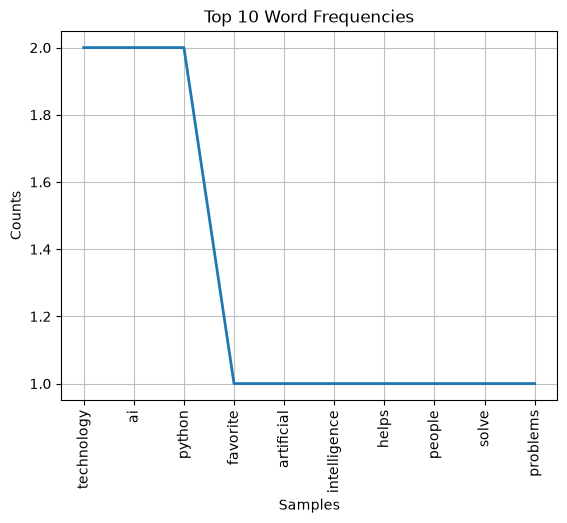

In [1]:
import re
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """My favorite technology is Artificial Intelligence.
AI helps people solve problems, analyze data, and build useful applications.
I enjoy learning Python because it makes programming easier and more interesting.
Technology continues to change education, healthcare, and communication.
I believe AI and Python will play an important role in the future."""

clean_text = re.sub(r'[^\w\s]', '', text.lower())

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("Words:", words)
print("Sentences:", sentences)

print("Using split():", clean_text.split())
print("Using word_tokenize():", word_tokenize(clean_text))

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("Filtered words:", filtered_words)

freq = FreqDist(filtered_words)
print("Word frequencies:", freq.most_common())

freq.plot(10, title="Top 10 Word Frequencies")
plt.show()

In [2]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
import nltk

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

words = [w for w in word_tokenize(text.lower()) if w.isalpha()]

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words]

print("Original:", filtered_words)
print("Stemmed:", stemmed_words)
print("Lemmatized:", lemmatized_words)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\manya\AppData\Roaming\nltk_data...


Original: ['favorite', 'technology', 'artificial', 'intelligence', 'ai', 'helps', 'people', 'solve', 'problems', 'analyze', 'data', 'build', 'useful', 'applications', 'enjoy', 'learning', 'python', 'makes', 'programming', 'easier', 'interesting', 'technology', 'continues', 'change', 'education', 'healthcare', 'communication', 'believe', 'ai', 'python', 'play', 'important', 'role', 'future']
Stemmed: ['favorit', 'technolog', 'artifici', 'intellig', 'ai', 'help', 'peopl', 'solv', 'problem', 'analyz', 'data', 'build', 'use', 'applic', 'enjoy', 'learn', 'python', 'make', 'program', 'easier', 'interest', 'technolog', 'continu', 'chang', 'educ', 'healthcar', 'commun', 'believ', 'ai', 'python', 'play', 'import', 'role', 'futur']
Lemmatized: ['favorite', 'technology', 'artificial', 'intelligence', 'ai', 'help', 'people', 'solve', 'problem', 'analyze', 'data', 'build', 'useful', 'application', 'enjoy', 'learning', 'python', 'make', 'programming', 'easier', 'interesting', 'technology', 'continue

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps analyze data.",
    "Blockchain provides secure digital transactions.",
    "Artificial intelligence and blockchain are useful technologies."
]

count_vectorizer = CountVectorizer()
count_matrix = count_vectorizer.fit_transform(texts)

print("Vocabulary:", count_vectorizer.get_feature_names_out())
print("Count Matrix:\n", count_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("TF-IDF Vocabulary:", tfidf_vectorizer.get_feature_names_out())
print("TF-IDF Matrix:\n", tfidf_matrix.toarray())

features = tfidf_vectorizer.get_feature_names_out()

for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]
    print(f"Text {i+1} keywords:",
          [(features[j], round(row[j], 3)) for j in top_indices])

Vocabulary: ['analyze' 'and' 'are' 'artificial' 'blockchain' 'data' 'digital' 'helps'
 'intelligence' 'provides' 'secure' 'technologies' 'transactions' 'useful']
Count Matrix:
 [[1 0 0 1 0 1 0 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 1 0 0 1 1 0 1 0]
 [0 1 1 1 1 0 0 0 1 0 0 1 0 1]]
TF-IDF Vocabulary: ['analyze' 'and' 'are' 'artificial' 'blockchain' 'data' 'digital' 'helps'
 'intelligence' 'provides' 'secure' 'technologies' 'transactions' 'useful']
TF-IDF Matrix:
 [[0.49047908 0.         0.         0.37302199 0.         0.49047908
  0.         0.49047908 0.37302199 0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.         0.35543247 0.
  0.46735098 0.         0.         0.46735098 0.46735098 0.
  0.46735098 0.        ]
 [0.         0.41756662 0.41756662 0.31757018 0.31757018 0.
  0.         0.         0.31757018 0.         0.         0.41756662
  0.         0.41756662]]
Text 1 keywords: [('data', np.float64(0.49)), ('helps', np.float64(0.49)), ('analyze', np.fl

In [4]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence helps automate tasks.
It is used in healthcare, education, and business."""

text2 = """Blockchain provides secure transactions.
Artificial intelligence can improve business operations."""

def preprocess(text):
    text = re.sub(r'[^\w\s]', '', text.lower())
    return text.split()

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1 & set2) / len(set1 | set2)
print("Jaccard Similarity:", round(jaccard, 4))

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]
print("Cosine Similarity:", round(cosine, 4))

Jaccard Similarity: 0.15
Cosine Similarity: 0.1533


In [5]:
%pip install textblob wordcloud

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   --------------------------------- ------ 524.3/625.0 kB 2.8 MB/s eta 0:00:01
   ---------------------------------------- 625.0/625.0 kB 1.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Review: This product is excellent and very easy to use.
Polarity: 0.78 | Sentiment: Positive

Review: The quality is amazing and I absolutely love it.
Polarity: 0.55 | Sentiment: Positive

Review: The product is average and works as expected.
Polarity: -0.12 | Sentiment: Negative

Review: The quality is poor and the product is disappointing.
Polarity: -0.50 | Sentiment: Negative

Review: I hate this product because it stopped working.
Polarity: -0.80 | Sentiment: Negative



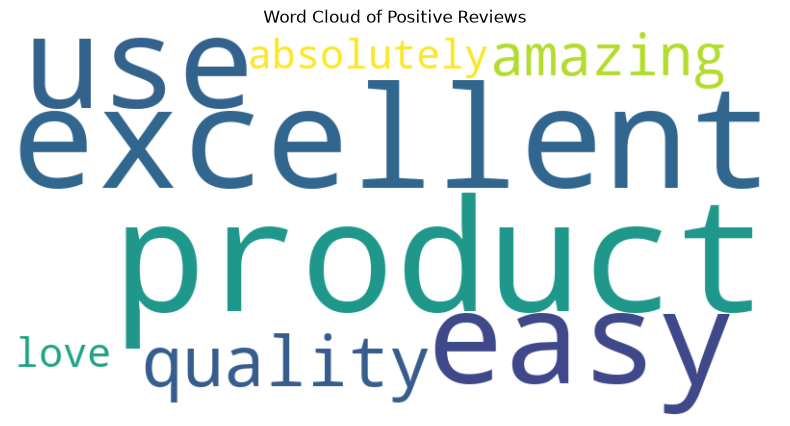

In [6]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This product is excellent and very easy to use.",
    "The quality is amazing and I absolutely love it.",
    "The product is average and works as expected.",
    "The quality is poor and the product is disappointing.",
    "I hate this product because it stopped working."
]

positive_reviews = []

for review in reviews:
    polarity = TextBlob(review).sentiment.polarity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"Review: {review}")
    print(f"Polarity: {polarity:.2f} | Sentiment: {sentiment}\n")

if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()

In [7]:
%pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
   ---------------------------------------- 0.8/350.9 MB 3.3 MB/s eta 0:01:45
   ---------------------------------------- 1.3/350.9 MB 3.9 MB/s eta 0:01:29
   ---------------------------------------- 2.1/350.9 MB 3.4 MB/s eta 0:01:42
   ---------------------------------------- 2.9/350.9 MB 3.4 MB/s eta 0:01:42
   ---------------------------------------- 3.1/350.9 MB 3.5 MB/s eta 0:01:39
   ---------------------------------------- 3.7/350.9 MB 2.9 MB/s eta 0:01:58
   ---------------------------------------- 4.2/350.9 MB 2.8 MB/s eta 0:02:06
    --------------------------------------- 5.0/350.9 MB 2.9 MB/s eta 0:02:00
    -----------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Artificial intelligence is transforming modern technology.
Machine learning allows computers to learn from data.
Natural language processing helps computers understand human language.
Deep learning uses neural networks to solve complex problems.
Python is widely used for artificial intelligence and data science.
Data preprocessing improves the quality of machine learning models.
Tokenization converts text into smaller units called tokens.
Text generation predicts the next word using previous words.
Neural networks learn patterns from training examples.
Artificial intelligence continues to create new opportunities.
"""

# Tokenize text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
sequences = []

for line in text.lower().split('.'):
    line = line.strip()
    if line:
        token_list = tokenizer.texts_to_sequences([line])[0]
        for i in range(1, len(token_list)):
            sequences.append(token_list[:i+1])

max_sequence_len = max(len(seq) for seq in sequences)
sequences = pad_sequences(
    sequences, maxlen=max_sequence_len, padding='pre'
)

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=150, verbose=0)

def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predictions = model.predict(token_list, verbose=0)
        predicted_id = int(np.argmax(predictions, axis=1)[0])

        output_word = next(
            (word for word, index in tokenizer.word_index.items()
             if index == predicted_id),
            ""
        )

        if not output_word:
            break

        seed_text += " " + output_word

    return seed_text

print(generate_text("artificial intelligence", 10))
print(generate_text("python is", 10))
print(generate_text("machine learning", 10))

C:\Users\manya\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


artificial intelligence is transforming modern technology technology science science science science science
python is widely used for artificial intelligence and data science science science
machine learning uses networks to to from data problems problems words words
